# Are Israeli supermarket prices competitive?
Analysis of ~13M price observations from six chains (Lobby 99 data on Kaggle).

**Questions:** how much do prices differ for the *same* item, what drives price, and how did price levels move over time?

To answer those questions, I wrote [`grocery_prices`](grocery_prices/) package. This notebook runs the code and shows the results. It can be reused for different supermarket databases, and you are encouraged to try it with your country's data.
Next, you can read a few details about the data pipeline and see the results.  

### Data cleaning
The raw data is about 13 million price rows from six big Israeli supermarket chains, joined from three sources: shelf prices, a manufacturer lookup and a store directory. Cleaning starts by dropping implausible prices (200 NIS or more, which are non-grocery items, and 0.2 NIS or less, which are coupons and placeholders). Then the "manufacturer lookup" fills in producers, and I keep only confident matches, so items with several candidate manufacturers count as unknown. Stores are linked to prices through a `store_code` that I rebuild from the store directory, because each chain formats it differently. Zip codes come from a separately geocoded file, and I check that its rows line up with the store directory before using it. Small banners are merged and the pharmacy banner is removed, so the sub-chain comparison stays meaningful. Rows with missing geography are kept, because only the regional analysis needs location, and observation time is taken from the scrape date and not from the date a price last changed.

### Code structure
The analysis is written in an object-oriented style, as a small Python package that this notebook only runs. Each class has one job and hides its details behind a simple interface, so the parts can be reused on other datasets. The dataset-specific work is confined to a `DatasetBuilder` (here `IsraelPricesBuilder`, which uses `DataLoader`, `StoreCatalog` and `PriceCleaner`), whose only job is to turn raw files into one standard table: item, price, chain, store, date and location. Every analysis is a subclass of one abstract `Analyzer` with a single `run(df)` method that works on that standard table. To analyze another country's retail prices, or another set of chains, you need to write one new builder. The rest of the existing pipeline runs unchanged. The code is modular, and to add a new analysis just to add one new `Analyzer` subclass, with no changes to the rest of the code. Analyzers never plot or write files, so each can be tested and reused alone, and all thresholds live in one `Config` object. The entire pipeline is tested on a synthetic dataset with known inflation.

In [1]:
import inspect, textwrap
from pathlib import Path
from IPython.display import Image, Markdown, display

from grocery_prices import Config, GroceryPricePipeline
from grocery_prices.analyzers import (Analyzer, AnalysisResult, PriceDispersionAnalyzer,
                                      PriceDriverAnalyzer, PriceIndexAnalyzer)
from grocery_prices.data import DatasetBuilder, PriceCleaner, StoreCatalog
from tests.test_pipeline import PipelineTests

def source(obj):
    """Display an object's source code, syntax-highlighted."""
    display(Markdown("```python\n" + textwrap.dedent(inspect.getsource(obj)) + "\n```"))

DATA_DIR, OUT_DIR = Path("data"), Path("outputs")
show = lambda stem: display(Image(OUT_DIR / "figures" / f"{stem}.png"))



### Design in code

The next two cells display the definition code for the main classes

In [2]:
source(Analyzer); source(AnalysisResult); source(DatasetBuilder)

```python
class Analyzer(ABC):
    name: ClassVar[str]

    def __init__(self, config: Config):
        self.config = config

    @abstractmethod
    def run(self, df: pd.DataFrame) -> AnalysisResult: ...

    @staticmethod
    def latest_snapshot(df: pd.DataFrame) -> pd.DataFrame:
        """Rows from the most recent scrape (one consistent point in time)."""
        return df[df["upload_date"] == df["upload_date"].max()]

```

```python
@dataclass
class AnalysisResult:
    name: str
    tables: dict[str, pd.DataFrame] = field(default_factory=dict)
    summary: dict[str, Any] = field(default_factory=dict)

```

```python
class DatasetBuilder(Protocol):
    """Anything with build() -> standard table can feed the pipeline.

    To analyse a different country or retailer, write one class like
    IsraelPricesBuilder below; analyzers, plotter and pipeline stay unchanged.
    """

    def build(self) -> pd.DataFrame: ...

```

### Data cleaning in code

In [3]:
source(StoreCatalog.build); source(PriceCleaner.clean)

```python
@staticmethod
def build(stores: pd.DataFrame) -> pd.DataFrame:
    he_to_en = {he: en for en, names in CHAIN_NAMES_HE.items() for he in names}
    s = stores.copy()
    s["chain"] = s["ChainName"].map(he_to_en)
    s = s.dropna(subset=["chain"])  # chains that never appear in the price data

    s["sub_chain_id"] = s["SubChainId"]
    for name, sub_id in RAMI_LEVY_SUB_CHAINS.items():
        s.loc[s["ChainName"] == name, "sub_chain_id"] = sub_id

    # Price files use "shu_001"; Rami Levy omits the underscore ("ram001").
    sep = s["chain"].eq("ramiLevi").map({True: "", False: "_"})
    s["store_code"] = s["chain"].str[:3] + sep + s["StoreId"].astype(str).str.zfill(3)

    s["city"] = s["City"].replace("unknown", np.nan)
    s["zip_code"] = pd.to_numeric(s["ZipCode"], errors="coerce")
    s["sub_chain_id"] = pd.to_numeric(s["sub_chain_id"], errors="coerce").astype("Int16")
    cols = ["store_code", "sub_chain_id", "city", "zip_code"]
    return s[cols].drop_duplicates("store_code").set_index("store_code")

```

```python
def clean(self, prices: pd.DataFrame) -> pd.DataFrame:
    df = self._filter_price_range(prices)
    df = self._attach_manufacturers(df)
    df = self._attach_stores(df)
    df = self._normalise_sub_chains(df)
    df = self._add_time_features(df)
    logger.info("Clean frame: %s rows x %d cols", f"{len(df):,}", df.shape[1])
    return df.reset_index(drop=True)

```

## running the Analysis

In [6]:
pipeline = GroceryPricePipeline(Config(data_dir=DATA_DIR, output_dir=OUT_DIR))
df = pipeline.build_dataset()
results = pipeline.analyse(df)
pipeline.export(results)

S = {name: r.summary for name, r in results.items()}   # headline numbers per analysis
print(f"{len(df):,} price observations, {df['store_code'].nunique()} stores, {df['item_code'].nunique():,} items")

d:\israel-grocery-prices\grocery_prices\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


16,971,644 price observations, 454 stores, 75,488 items


## 1. Same item, different chain: how much does the price differ?

Median price spread for one item: 3.0% inside a chain vs 6.8% between chains.


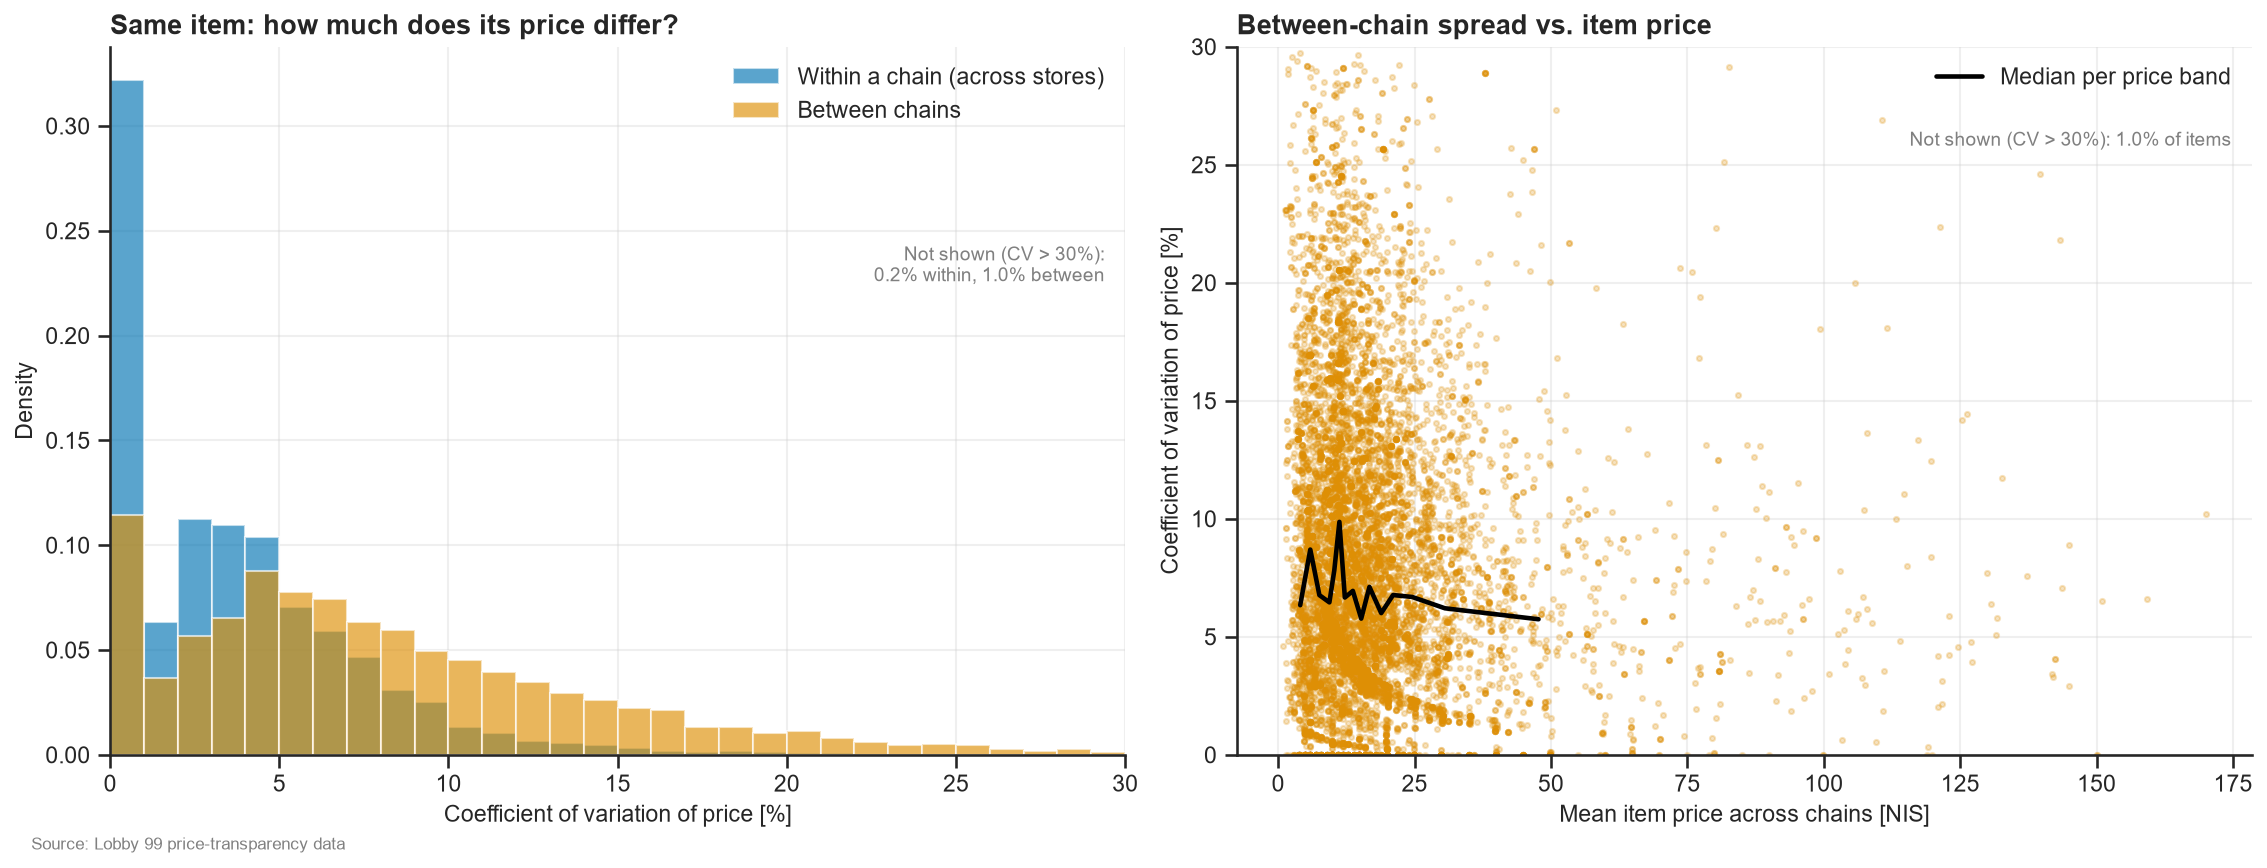

In [7]:
d = S["price_dispersion"]
print(f"Median price spread for one item: {d['median_cv_within_chain_pct']:.1f}% inside a chain "
      f"vs {d['median_cv_between_chains_pct']:.1f}% between chains.")
show("01_price_dispersion")

**How it's computed:** coefficient of variation per item, on the latest snapshot only, so every price is from the same point in time.

**Conclusions:** Not surprisingly, prices vary more between chains. The variation is largest around 10 NIS, and can reach up to 85%. 

In [6]:
source(PriceDispersionAnalyzer.run)

```python
def run(self, df: pd.DataFrame) -> AnalysisResult:
    c = self.config
    snap = self.latest_snapshot(df)

    within = (
        snap.groupby(["item_code", "chain"], observed=True)["price"]
        .agg(mean="mean", std="std", n_stores="count")
        .reset_index()
    )
    within = within[within["n_stores"] >= c.min_stores_per_item].copy()
    within["cv_pct"] = 100 * within["std"] / within["mean"]

    chain_prices = snap.groupby(["item_code", "chain"], observed=True)["price"].median().reset_index()
    between = (
        chain_prices.groupby("item_code")["price"]
        .agg(mean_price="mean", std_price="std", n_chains="count")
        .reset_index()
    )
    between = between[between["n_chains"] >= c.min_chains_per_item].copy()
    between["cv_pct"] = 100 * between["std_price"] / between["mean_price"]

    pricey = between["mean_price"] >= c.expensive_item_threshold
    summary = {
        "snapshot_date": str(snap["upload_date"].max().date()),
        "n_items_compared": len(between),
        "median_cv_within_chain_pct": within["cv_pct"].median(),
        "median_cv_between_chains_pct": between["cv_pct"].median(),
        "share_items_identical_price_within_chain": (within["cv_pct"] == 0).mean(),
        "median_cv_expensive_items_pct": between.loc[pricey, "cv_pct"].median(),
        "median_cv_cheap_items_pct": between.loc[~pricey, "cv_pct"].median(),
        "median_std_nis_expensive_items": between.loc[pricey, "std_price"].median(),
        "median_std_nis_cheap_items": between.loc[~pricey, "std_price"].median(),
    }
    return AnalysisResult(self.name, {"within_chain": within, "between_chains": between}, summary)

```

## 2. What explains price?

Item identity alone explains 98% of price variance.
Of what is left: chain 4.9%, city 11.9%, quarter 0.5%.


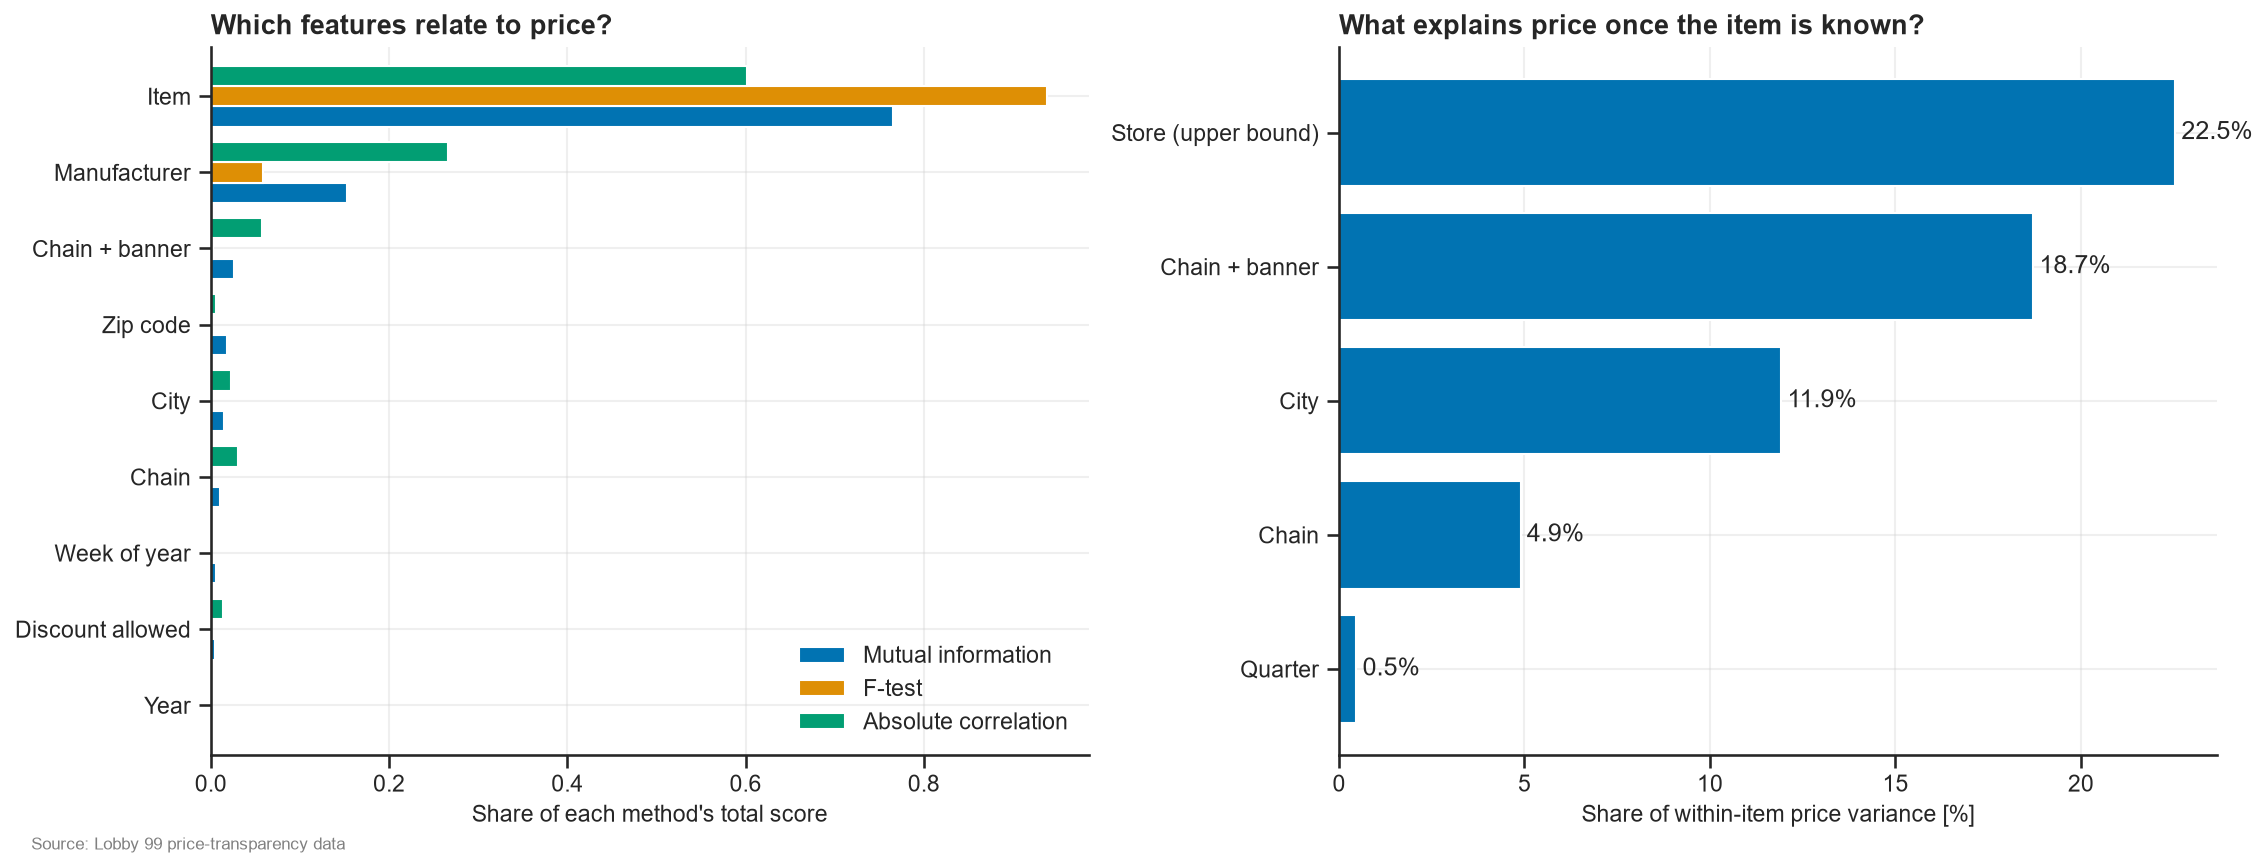

In [8]:
p = S["price_drivers"]
print(f"Item identity alone explains {p['item_identity_explains_log_price_variance_pct']:.0f}% of price variance.")
print(f"Of what is left: chain {p['within_item_chain_pct']:.1f}%, city {p['within_item_city_pct']:.1f}%, "
      f"quarter {p['within_item_quarter_pct']:.1f}%.")
show("02_price_drivers")

**How it's computed:** remove each item's average log price, then measure how much of the remaining variation each factor explains (between-group sum of squares / total).

In [ ]:
source(PriceDriverAnalyzer._within_item_variance)

## 3. Price level over time: why the method matters
Averaging all prices each quarter (dashed) shifts whenever the product mix changes. A matched-item index (solid) compares only items present in consecutive quarters.

osherAd     matched   -1.5%   naive   +2.4%
ramiLevi    matched   +1.6%   naive   +5.2%
shufersal   matched   -1.8%   naive   +0.2%
victory     matched   +0.6%   naive   +2.6%
yenotBitan  matched   +2.3%   naive   +2.6%
yohananof   matched   +2.6%   naive   +4.5%


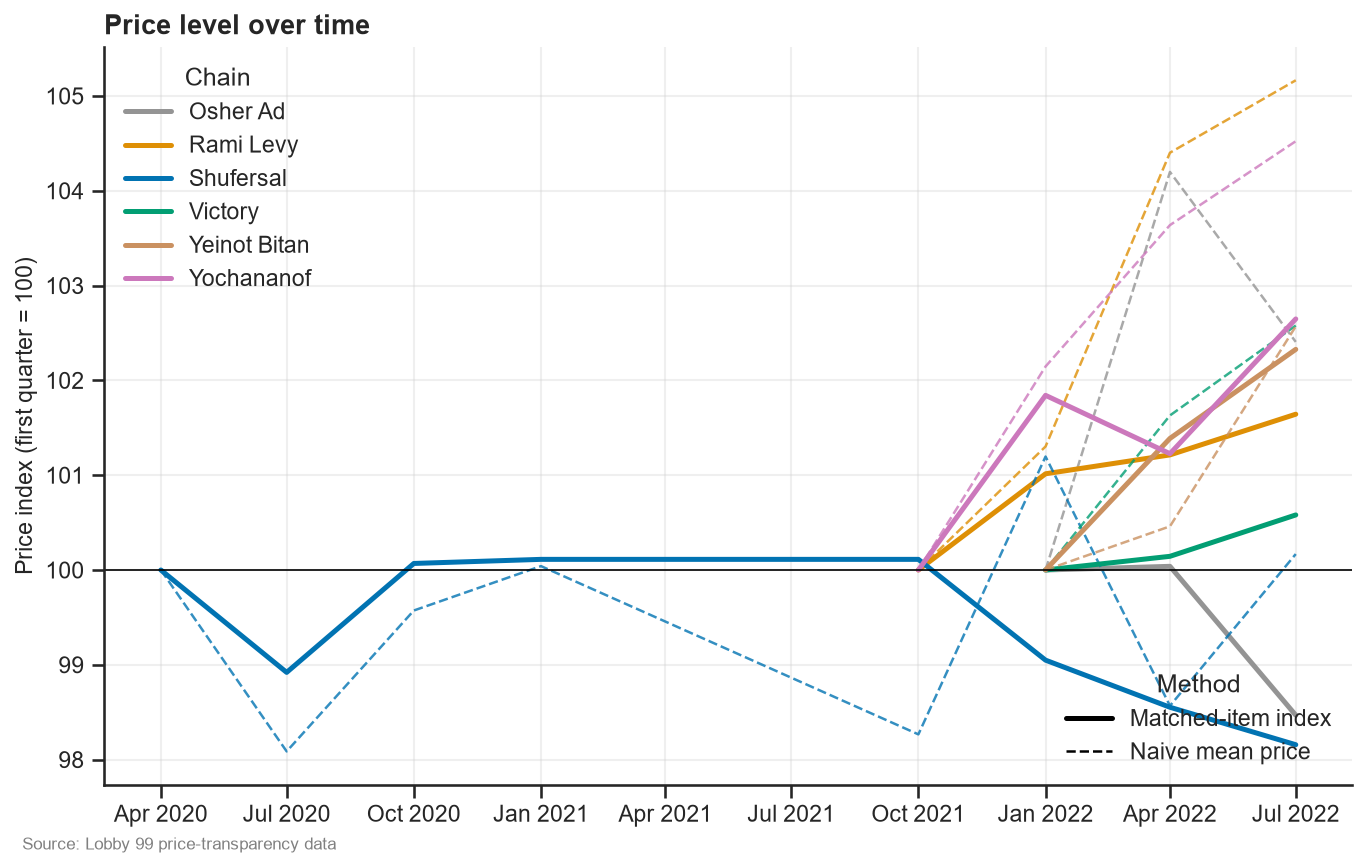

In [9]:
ix = S["price_index"]
for chain, pct in ix["matched_index_total_change_pct"].items():
    naive = ix["naive_mean_total_change_pct"].get(chain, float("nan"))
    print(f"{chain:<11} matched {pct:+6.1f}%   naive {naive:+6.1f}%")
show("04_price_index")

**How it's computed:** a chained Jevons index. Per chain, log price changes between consecutive quarters on matched items are averaged, then chained.

In [ ]:
source(PriceIndexAnalyzer.run)

**How I know it works:** the tests generate fake data with a known 2% quarterly inflation and check that the index recovers it.

In [ ]:
source(PipelineTests.test_matched_index_recovers_known_inflation)

## 4. How concentrated is the product range?

27 manufacturers have >200 items in some chain and supply 55% of all listed items.


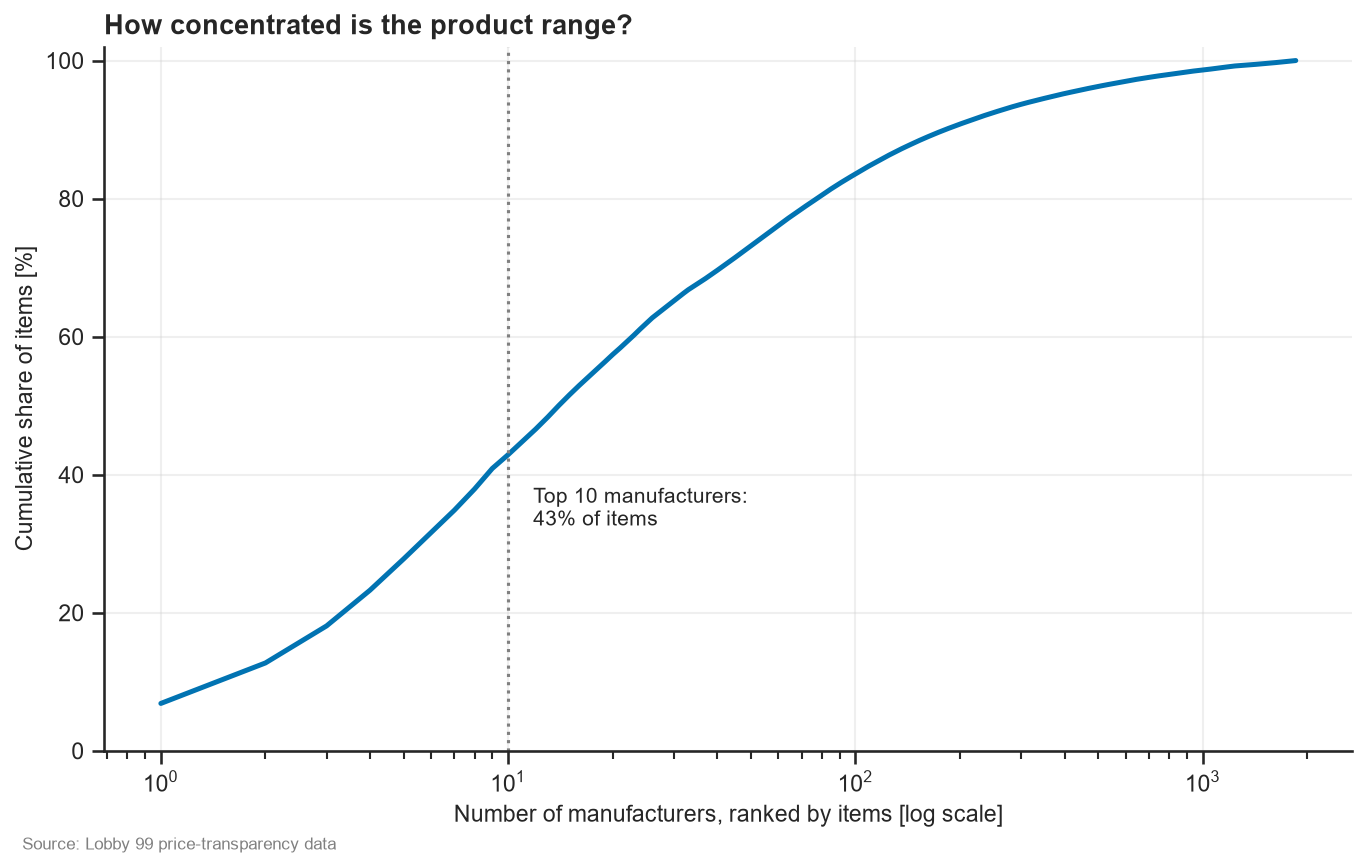

In [10]:
m = S["manufacturer_concentration"]
print(f"{m['n_big_manufacturers']} manufacturers have >{pipeline.config.big_manufacturer_min_items} items in some chain "
      f"and supply {m['big_manufacturers_share_of_items_pct']:.0f}% of all listed items.")
show("06_manufacturers_concentration")

## 5. Regional prices (adjusted for product mix)

2022: cheapest district Negev, most expensive Tel Aviv.


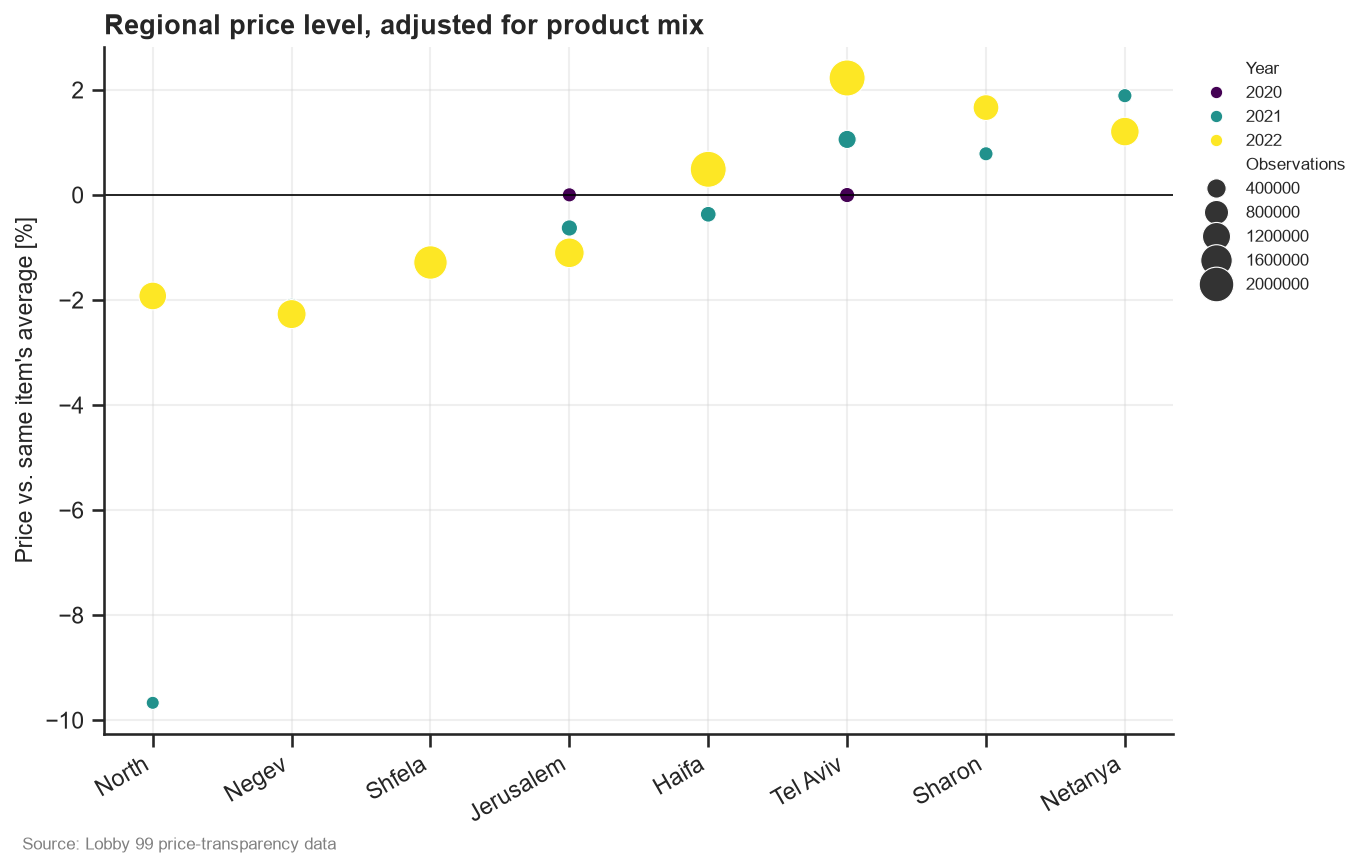

In [11]:
r = S["regional_prices"]
print(f"{r['latest_year']}: cheapest district {r['cheapest_district_latest_year']}, "
      f"most expensive {r['most_expensive_district_latest_year']}.")
show("07_regional_prices")

## Method notes
- **Observation date:** `upload_date`, not `PriceUpdateDate` (which is when a price last *changed*).
- **Matched-item index** instead of a raw mean, so basket changes don't masquerade as inflation.
- **Within-item variance decomposition** instead of PCA, to separate "what the product is" from "where it is sold".
- Full source, tests and methodology: see the repository README.